# Part 1: Exploratory Data Analysis (EDA)
This notebook performs EDA on the cleaned primary training dataset for ISCOR AI.
It includes:
1. Class balance of the target label (Risk_Category)
2. Missingness matrix
3. Correlation heatmap of the unified features


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


In [2]:
# Load the cleaned primary dataset
df = pd.read_csv('../datasets/primary_dataset_clean.csv')
df.head()


,Age,Gender,Sleep_Hours,Academic_Pressure,Financial_Stress,Social_Support,Study_Hours,Physical_Activity,Family_History,Risk_Category
0,0.518094,0,0.852935,0.289865,-0.422995,-0.162281,-1.149715,-0.039908,0,Moderate
1,0.258604,1,-0.538148,-1.104745,0.250383,-1.586703,1.144879,-1.121898,0,Moderate
2,-1.038850,1,0.852935,0.987170,0.923761,-0.162281,-1.608634,-1.121898,0,High
3,-1.038850,0,-0.538148,-0.407440,0.923761,-0.162281,-0.461337,-1.121898,0,Low
4,-1.298340,0,0.852935,0.289865,-1.096372,1.262141,0.227041,-1.121898,0,High


## 1. Class Balance (Risk Category)


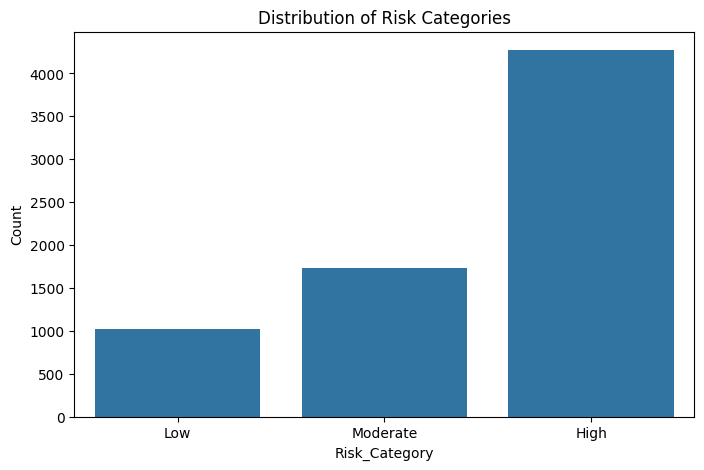

Risk_Category
High        60.837368
Moderate    24.636856
Low         14.525776
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Risk_Category', order=['Low', 'Moderate', 'High'])
plt.title('Distribution of Risk Categories')
plt.ylabel('Count')
plt.show()

print(df['Risk_Category'].value_counts(normalize=True) * 100)


## 2. Missingness


In [4]:
# We already imputed missing values during preprocessing, but let's verify
missing = df.isnull().sum()
print("Missing values per column:\n", missing[missing > 0])
if missing.sum() == 0:
    print("No missing values found!")


Missing values per column:
 Series([], dtype: int64)
No missing values found!


## 3. Correlation Heatmap


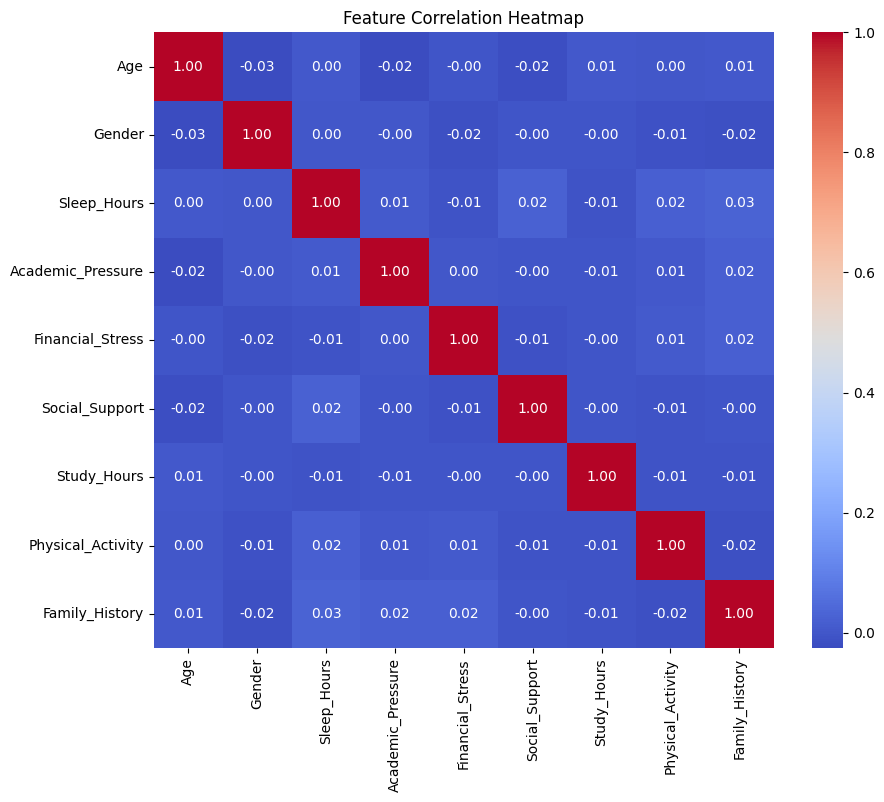

In [5]:
# Compute correlation matrix for numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Heatmap')
plt.show()
